In [18]:
import pickle

root = "/Users/lwu/PycharmProjects/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW"
file_path = "/Analysis/checkUnmatchedGenes_readCountSums/archs4_geneSymbolNames_list.pkl"

pickle_in = open(root + file_path, 'rb')
geneNames_list = pickle.load(pickle_in)
pickle_in.close()

# Check samples names size is 620k
print("ARCHS4 Total # Genes:", len(geneNames_list))

############################################################################################################

file_path = "/data_results/matched_genes_bt_gConvertCsv_GLF.pkl"

pickle_in = open(root + file_path, 'rb')
geneName_converter_dict = pickle.load(pickle_in)
pickle_in.close()

# Check number of matched genes
print("Total # Matched Genes:", len(geneName_converter_dict))

ARCHS4 Total # Genes: 62548
Total # Matched Genes: 57766


In [34]:
# Matched genes are mapping ARCHS4 unique gene symbols to GLF unique gene symbol names through ENSG IDS
# However, sometimes the ENSG IDS may map to several genes so there may be duplicates
# Check the mapped GLD symbols for uniqueness

print("Total # Unique Matched Genes (GLF):", len(list(set(list(geneName_converter_dict.values())))))
print("Total # Repeated Matched Genes:", 57766-57587)

Total # Unique Matched Genes (GLF): 57587
Total # Repeated Matched Genes: 179


In [36]:
from collections import Counter

value_counts = Counter(geneName_converter_dict.values())
duplicate_matched_genes = []
for key, value in geneName_converter_dict.items():
    if value_counts[value] > 1:
        duplicate_matched_genes.append((key,value,value_counts[value]))

print(duplicate_matched_genes)
print(len(duplicate_matched_genes))

[('ABCF2', 'ABCF2-H2BE1', 2), ('ABCF2-H2BK1', 'ABCF2-H2BE1', 2), ('ACTR3BP2', 'ACTR3BP6', 2), ('ACTR3BP6', 'ACTR3BP6', 2), ('ADHFE1', 'RP11-346I3.5', 2), ('ALG1L9P', 'ALG1L9P', 2), ('ARL17A', 'ARL17B', 2), ('ARL17B', 'ARL17B', 2), ('BABAM1', 'CTD-2278I10.6', 2), ('BAZ2B', 'AC009961.3', 2), ('BCL2L2', 'BCL2L2-PABPN1', 2), ('BCL2L2-PABPN1', 'BCL2L2-PABPN1', 2), ('BOLA2-SMG1P6', 'BOLA2-SMG1P6', 2), ('BOLA2B', 'BOLA2-SMG1P6', 2), ('BORCS8-MEF2B', 'MEF2B', 2), ('BPY2', 'BPY2C', 2), ('BPY2C', 'BPY2C', 2), ('C4B', 'C4A', 2), ('C4B_2', 'C4A', 2), ('C8ORF44-SGK3', 'C8orf44-SGK3', 2), ('CACNB4', 'CTD-2021K4.1', 2), ('CALM1', 'CALM1', 2), ('CALM2', 'CALM1', 2), ('CBWD3', 'CBWD6', 2), ('CBWD6', 'CBWD6', 2), ('CCDC144A', 'RP11-219A15.1', 2), ('CD59', 'RP4-541C22.8', 2), ('CDRT4', 'TVP23C-CDRT4', 3), ('CDY1', 'CDY1B', 2), ('CDY1B', 'CDY1B', 2), ('CGB3', 'CGB8', 2), ('CGB5', 'CGB7', 2), ('CGB7', 'CGB7', 2), ('CGB8', 'CGB8', 2), ('CHML', 'CHML', 2), ('CHN2', 'RP5-1189D6.2', 2), ('CHTF8', 'DERPC', 2), 

In [29]:
import numpy as np

decoded_geneNames_list = [i.decode() for i in geneNames_list]

not_found = []

keys_set = list(geneName_converter_dict.keys())
for string in decoded_geneNames_list:
    if string not in keys_set:
        index = np.where(decoded_geneNames_list == string)
        not_found.append((index,string))

print("Unmatched gens:", len(not_found))
print(not_found[0:10])

Unmatched gens: 5096
[(array([], dtype=int64), 'ACAT1'), (array([], dtype=int64), 'ACP1'), (array([], dtype=int64), 'ACTBP8'), (array([], dtype=int64), 'ADAM23'), (array([], dtype=int64), 'ADRA1D'), (array([], dtype=int64), 'AGXT'), (array([], dtype=int64), 'AKR1B10'), (array([], dtype=int64), 'ALPK3'), (array([], dtype=int64), 'AMN'), (array([], dtype=int64), 'AQP7')]


In [30]:
import numpy as np

decoded_geneNames_list = [i.decode() for i in geneNames_list]

not_found = []

keys_set = list(geneName_converter_dict.keys())
for string in decoded_geneNames_list:
    if string not in keys_set:
        index = np.where(decoded_geneNames_list == string)
        not_found.append((index,string))

print("Unmatched gens:", len(not_found))
print(not_found[0:10])

Unmatched gens: 5096
[((array([], dtype=int64),), 'ACAT1'), ((array([], dtype=int64),), 'ACP1'), ((array([], dtype=int64),), 'ACTBP8'), ((array([], dtype=int64),), 'ADAM23'), ((array([], dtype=int64),), 'ADRA1D'), ((array([], dtype=int64),), 'AGXT'), ((array([], dtype=int64),), 'AKR1B10'), ((array([], dtype=int64),), 'ALPK3'), ((array([], dtype=int64),), 'AMN'), ((array([], dtype=int64),), 'AQP7')]


In [25]:
decoded_geneNames_list[0]

'A1BG'

In [28]:
keys_set[0]

'A1BG'

In [ ]:
pickle_in = open(root + file_path, 'rb')
geneNames_list = pickle.load(pickle_in)
pickle_in.close()

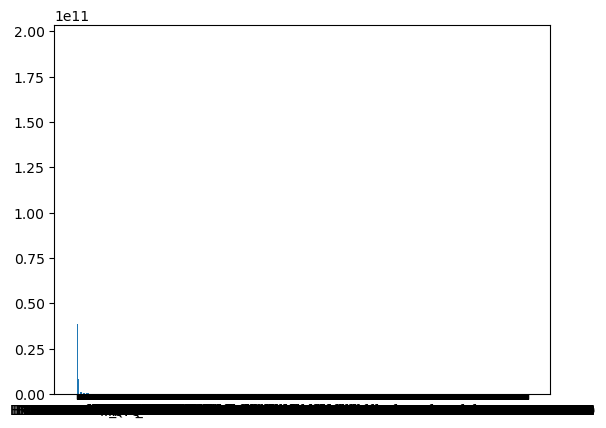

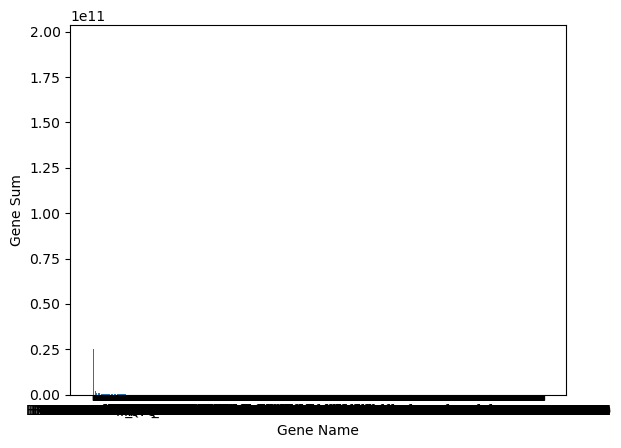

In [59]:
import pickle

pickle_in = open(root + file_path, 'rb')
geneNames_list = pickle.load(pickle_in)
pickle_in.close()

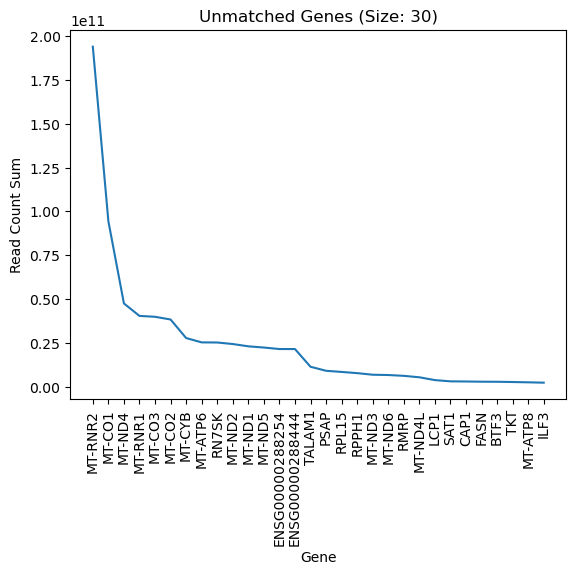

In [67]:
import csv
import matplotlib.pyplot as plt

# Open the CSV file and read in the data
with open("unmatched_gene_name_readCountSum.csv", 'r') as f:
    reader = csv.reader(f)
    next(reader)  # Skip the header row
    data = [row for row in reader]

# Unpack the data into separate lists
gene_names, gene_readCountSum = zip(*data)

# Convert list to integer
gene_readCountSum = list(map(int, gene_readCountSum))

# Plot the data using matplotlib
plt.plot(gene_names[0:30], gene_readCountSum[0:30])

# Add labels to the plot
plt.xlabel('Gene')
plt.xticks(rotation=90)
plt.ylabel('Read Count Sum')
plt.title('Unmatched Genes (Size: 30)')

# Show the plot
plt.show()


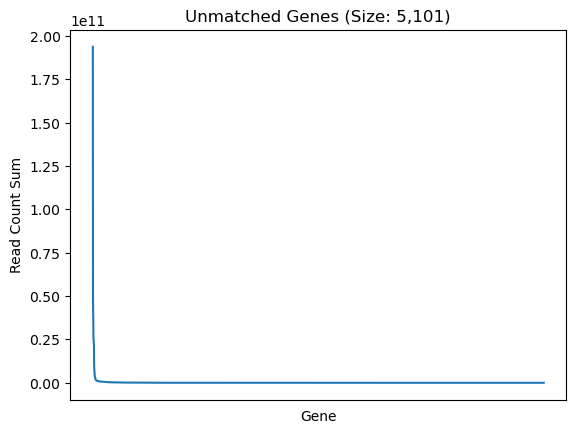

In [70]:
import csv
import matplotlib.pyplot as plt

# Open the CSV file and read in the data
with open("unmatched_gene_name_readCountSum.csv", 'r') as f:
    reader = csv.reader(f)
    next(reader)  # Skip the header row
    data = [row for row in reader]

# Unpack the data into separate lists
gene_names, gene_readCountSum = zip(*data)

# Convert list to integer
gene_readCountSum = list(map(int, gene_readCountSum))

# Plot the data using matplotlib
plt.plot(gene_names, gene_readCountSum)

# Add labels to the plot
plt.xlabel('Gene')
plt.xticks([])
#plt.xticks(rotation=90)

plt.ylabel('Read Count Sum')
plt.title('Unmatched Genes (Size: 5,101)')

# Show the plot
plt.show()


In [62]:
gene_names[0:3]

('MT-RNR2', 'MT-CO1', 'MT-ND4')

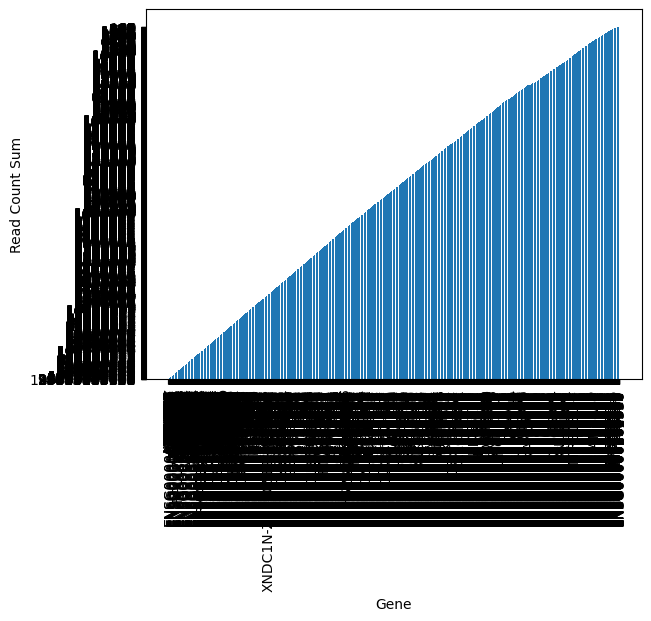

In [63]:
# Plot the data using matplotlib
plt.bar(gene_names, gene_readCountSum)

# Add labels to the plot
plt.xlabel('Gene')
plt.xticks(rotation=90)
plt.ylabel('Read Count Sum')

# Show the plot
plt.show()
